## Classification simple avec CNN
Un exemple de classification à l'aide d'un réseau de neurones convolutifs pour le célèbre jeu de données MNIST.

## Objectifs :
- Reconnaître des chiffres manuscrits
- Comprendre le principe d'un classificateur de réseau CNN
- Implémentation avec Keras

Le jeu de données MNIST (Modified National Institute of Standards and Technology) est un incontournable du Deep Learning.
Il se compose de 60 000 petites images de chiffres manuscrits pour l'apprentissage et de 10 000 pour le test.

## Ce que nous allons faire :
- Récupérer les données
- Préparer les données
- Créer un modèle
- Entraîner le modèle
- Évaluer le résultat


## Step 1 - Importation des librairies 

In [1]:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys,os
from importlib import reload

2024-03-01 15:32:02.810192: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Step 2 - Récupération et remodelage des données 
MNIST est l'un des ensembles de données historiques les plus célèbres.  
Il est inclus dans [Keras datasets](https://www.tensorflow.org/api_docs/python/tf/keras/datasets)

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1,28,28,1)
x_test  = x_test.reshape(-1,28,28,1)

print("x_train : ",x_train.shape)
print("y_train : ",y_train.shape)
print("x_test  : ",x_test.shape)
print("y_test  : ",y_test.shape)

x_train :  (60000, 28, 28, 1)
y_train :  (60000,)
x_test  :  (10000, 28, 28, 1)
y_test  :  (10000,)


In [14]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

- La première dimension (60000) peut être vue comme le nombre de lignes, chaque ligne étant une image unique.
- La deuxième et la troisième dimension (28, 28) représentent les dimensions de chaque image (hauteur et largeur, respectivement).
- La quatrième dimension (1) représente le nombre de canaux de couleur de chaque image.

Même si les images de MNIST sont en niveaux de gris et n'ont qu'un seul canal de couleur, le CNN attend toujours un tableau d'entrée en 4D, où la quatrième dimension représente le nombre de canaux de couleur.

## Step 3 - Preparation des données 

In [3]:
print('Avant normalisation : Min={}, max={}'.format(x_train.min(),x_train.max()))

xmax=x_train.max()
x_train = x_train / xmax
x_test  = x_test  / xmax

print('Apres normalisation  : Min={}, max={}'.format(x_train.min(),x_train.max()))

Avant normalisation : Min=0, max=255
Apres normalisation  : Min=0.0, max=1.0


### Visualisons 

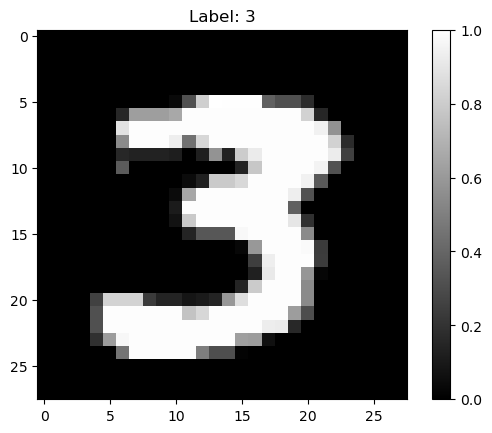

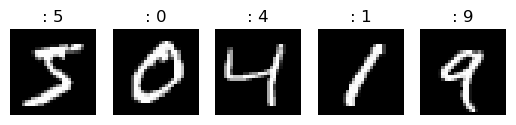

In [4]:
# visualisons une image
plt.imshow(x_train[27].reshape(28, 28), cmap='gray')
plt.title(f"Label: {y_train[27]}")
plt.colorbar()  # pour afficher la barre de couleur indiquant l'intensité des pixels
plt.show()

# visualisons les 5 premieres images
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f": {y_train[i]}")
    plt.axis('off')  # pour désactiver les axes

plt.show()

## Step 4 - Creation du model
Quelques liens Utiles  : 
 - [Optimizer](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers)
 - [Activation](https://www.tensorflow.org/api_docs/python/tf/keras/activations)
 - [Loss](https://www.tensorflow.org/api_docs/python/tf/keras/losses)
 - [Metrics](https://www.tensorflow.org/api_docs/python/tf/keras/metrics)

In [5]:
model = keras.models.Sequential()

model.add( keras.layers.Input((28,28,1)) )

model.add( keras.layers.Conv2D(8, (3,3),  activation='relu') )
model.add( keras.layers.MaxPooling2D((2,2)))
model.add( keras.layers.Dropout(0.2))

model.add( keras.layers.Conv2D(16, (3,3), activation='relu') )
model.add( keras.layers.MaxPooling2D((2,2)))
model.add( keras.layers.Dropout(0.2))

model.add( keras.layers.Flatten()) 
model.add( keras.layers.Dense(100, activation='relu'))
model.add( keras.layers.Dropout(0.5))

model.add( keras.layers.Dense(10, activation='softmax'))

In [6]:
model.summary()

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 8)         0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 13, 13, 8)         0         
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 16)          0         
 g2D)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 5, 5, 16)          0

## Step 5 - Apprentissage du modèle 

In [15]:
batch_size  = 512
epochs      =  16

history = model.fit(  x_train, y_train,
                      batch_size      = batch_size,
                      epochs          = epochs,
                      validation_data = (x_test, y_test))

Epoch 1/16
118/118 [==============================] - 5s 37ms/step - loss: 1.0685 - accuracy: 0.6510 - val_loss: 0.2388 - val_accuracy: 0.9354
Epoch 2/16
118/118 [==============================] - 5s 39ms/step - loss: 0.3461 - accuracy: 0.8949 - val_loss: 0.1352 - val_accuracy: 0.9606
Epoch 3/16
118/118 [==============================] - 5s 41ms/step - loss: 0.2422 - accuracy: 0.9260 - val_loss: 0.1042 - val_accuracy: 0.9685
Epoch 4/16
118/118 [==============================] - 5s 41ms/step - loss: 0.2052 - accuracy: 0.9384 - val_loss: 0.0849 - val_accuracy: 0.9733
Epoch 5/16
118/118 [==============================] - 5s 44ms/step - loss: 0.1791 - accuracy: 0.9464 - val_loss: 0.0743 - val_accuracy: 0.9765
Epoch 6/16
118/118 [==============================] - 5s 46ms/step - loss: 0.1640 - accuracy: 0.9504 - val_loss: 0.0693 - val_accuracy: 0.9769
Epoch 7/16
118/118 [==============================] - 6s 47ms/step - loss: 0.1524 - accuracy: 0.9535 - val_loss: 0.0625 - val_accuracy: 0.9803

## Step 6 - Evaluation du modèle 
### 6.1 - Final loss et accuracy

In [16]:
score = model.evaluate(x_test, y_test, verbose=0)

print(f'Test loss     : {score[0]:4.4f}')
print(f'Test accuracy : {score[1]:4.4f}')

Test loss     : 0.0445
Test accuracy : 0.9862


### 6.2 - Plot history

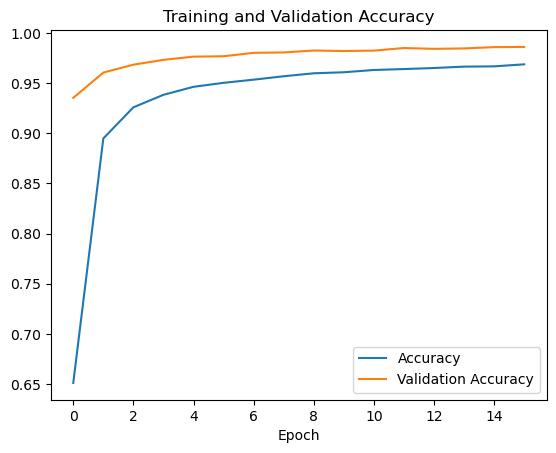

In [17]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend(loc='lower right')
plt.xlabel('Epoch')
plt.title('Training and Validation Accuracy')

plt.show()

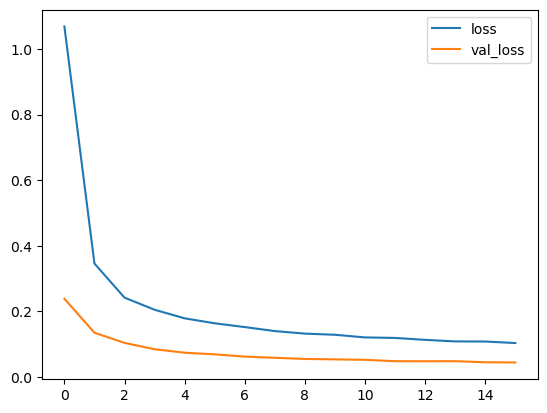

In [18]:
# Affichons les courbes d'apprentissage
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot();

### 6.3 - Affichons quelques résultats de prediction

313/313 [==============================] - 2s 8ms/step


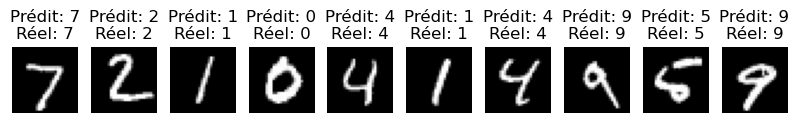

In [19]:
y_softmax = model.predict(x_test)
y_pred    = np.argmax(y_softmax, axis=-1)

# Afficher les 5 premières images de x_test avec les étiquettes prédites et réelles
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')  # les images sont de taille 28x28
    plt.title(f"Prédit: {y_pred[i]}\nRéel: {y_test[i]}")
    plt.axis('off')  # Enlever les axes
plt.show()

## Affichons quelques erreurs

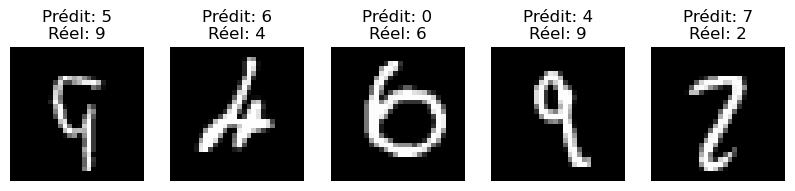

In [20]:
# Trouver les indices où les prédictions sont incorrectes
incorrects = np.nonzero(y_pred != y_test)[0]

# Afficher les 5 premières images incorrectes
plt.figure(figsize=(10, 5))
for i, incorrect in enumerate(incorrects[:5]):  # Modifier ici pour afficher plus ou moins d'images
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[incorrect].reshape(28, 28), cmap='gray')  # Suppose que les images sont de taille 28x28
    plt.title(f"Prédit: {y_pred[incorrect]}\nRéel: {y_test[incorrect]}")
    plt.axis('off')  # Enlever les axes
plt.show()

## Affichons la matrice de confusion

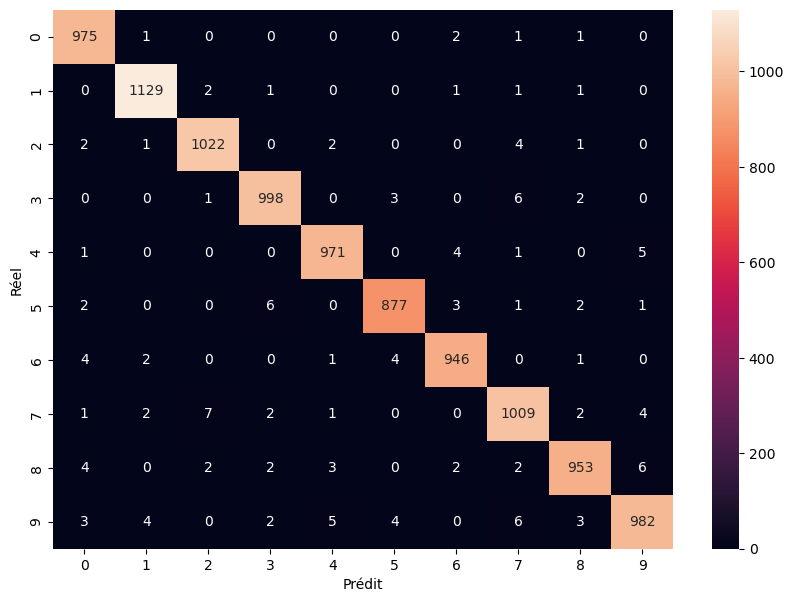

In [21]:
# Supposons que y_test contient les étiquettes réelles
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

Voici quelques exemples de ce que vous pouvez faire pour vous amuser :

- Modifier l'architecture du réseau (couches, nombre de neurones, etc.)
- Afficher un résumé du réseau
- Récupérer et afficher la sortie softmax du réseau, pour l'évaluer

## Exercices

# Exercice 1: Classification d'Images (Dataset: CIFAR-10)

Le CIFAR-10 dataset est une collection de 60 000 images couleurs 32x32 réparties en 10 classes, avec 6 000 images par classe. Les classes sont:

- Avion
- Automobile
- Oiseau
- Chat
- Cerf
- Chien
- Grenouille
- Cheval
- Bateau
- Camion

Objectif:
Construire un modèle CNN pour classifier les images du jeu de données CIFAR-10 en 10 classes différentes.

Tâches:
- Charger le jeu de données CIFAR-10.
- Pré-traitement des images.
- Construire un modèle CNN.
- Entraîner le modèle et valider sa performance.
- Visualiser quelques prédictions.
- Matrice de confusion

# Exercice 2: Classification d'Images Médicales (Dataset: Chest X-Ray Images)

vous êtes chargé de construire un modèle CNN pour détecter la pneumonie à partir d'images radiographiques thoraciques. Ce dataset est organisé en trois dossiers (un pour le training, un pour le testing, et un pour la validation) et contient des sous-dossiers pour chaque catégorie d'image (Pneumonia/Normal). Il y a 5 863 images de rayons X (JPEG) et 2 catégories (Pneumonie et Normal).

Objectif: Construire un modèle CNN pour détecter la pneumonie à partir d'images radiographiques thoraciques.

Tâches:
- Charger le jeu de données Chest X-Ray Image: 
- Pré-traitement des images.
- Construire un modèle CNN.
- Entraîner le modèle et valider sa performance.
- Afficher la matrice de confusion, la précision, le rappel et le F1-score.
- Visualiser quelques images de rayons X avec les étiquettes prédites et réelles.

[Dataset](https://data.mendeley.com/datasets/rscbjbr9sj/2)